In [48]:
!pip install -q transformers pandas matplotlib

In [49]:
import pandas as pd
import re
import matplotlib.pyplot as plt
from transformers import AutoTokenizer


In [50]:
# Project Name
project_name = "nasser"

# Project Dataset (موضوع البلاغات البلدية -)

data = {
    "language": ["ar", "ar", "ar", "ar", "ar", "ar"],
    "text": [
        "    انقطاع     الماء    اليوم   \n",
        "  تعطل     اشارة     \n المرور     ",
        "   تراكم      النفايات  \n  بالشارع   ",
        "    ضعف      انارة  \n   الممر    ",
        "  تاخر   \n  صيانة      الرصيف     ",
        "    تسرب \n  مياه     قرب     الحي   "
    ]
}

df = pd.DataFrame(data)
df["word_count"] = df["text"].str.split().str.len()

# Confirmation
print("Project:", project_name)
print("Dataset ready! Rows:", len(df))

# Display Dataset
display(df)

Project: nasser
Dataset ready! Rows: 6


,language,text,word_count
0,ar,انقطاع الماء اليوم \n,3
1,ar,تعطل اشارة \n المرور,3
2,ar,تراكم النفايات \n بالشارع,3
3,ar,ضعف انارة \n الممر,3
4,ar,تاخر \n صيانة الرصيف,3
5,ar,تسرب \n مياه قرب الحي,4


In [51]:
# Lab 1 - Code 4: Text Normalisation
import re
from IPython.display import HTML, display

def normalize_report_text(text):
    # توحيد المسافات الداخلية وحذف المسافات الزائدة في البداية والنهاية
    return re.sub(r"\s+", " ", str(text)).strip()

df["clean_text"] = df["text"].apply(normalize_report_text)

print("✅ Normalisation Completed!")
html_table = df[["text", "clean_text"]].to_html(index=False)
html_styled = f'<div style="white-space: pre-wrap;">{html_table}</div>'
display(HTML(html_styled))

✅ Normalisation Completed!


text,clean_text
انقطاع الماء اليوم \n,انقطاع الماء اليوم
تعطل اشارة \n المرور,تعطل اشارة المرور
تراكم النفايات \n بالشارع,تراكم النفايات بالشارع
ضعف انارة \n الممر,ضعف انارة الممر
تاخر \n صيانة الرصيف,تاخر صيانة الرصيف
تسرب \n مياه قرب الحي,تسرب مياه قرب الحي


In [52]:
# Lab 1 - Code 5: PII Masking

# Add Sample Personal Information & Report Codes across rows (0 to 5)
df.loc[0, "clean_text"] = (
    "انقطاع الماء اليوم، للتواصل على الجوال 0547788990 أو "
    "water.support@baladiya-test.sa"
)
df.loc[1, "clean_text"] = (
    "تعطل اشارة المرور بشكل متكرر، رقم البلاغ REP-4012"
)
df.loc[2, "clean_text"] = (
    "تراكم النفايات بالشارع وأحتاج متابعة، راسلوني على "
    "sanitation.team@baladiya-test.sa أو 0561122334"
)
df.loc[3, "clean_text"] = (
    "ضعف انارة الممر ليلاً، مرجع البلاغ REPORT-805 والجوال "
    "0539988112"
)
df.loc[4, "clean_text"] = (
    "تاخر صيانة الرصيف وتكسرات خطيرة، إيميلي "
    "roads.fix@baladiya-test.sa"
)
df.loc[5, "clean_text"] = (
    "تسرب مياه قرب الحي منذ الصباح، رقم البلاغ REP-9104"
)

# Define Masking Function
def mask_pii(text):
    text = str(text)

    # 1. Mask Email Addresses
    text = re.sub(r'\b[\w.+-]+@[\w-]+\.[A-Za-z]{2,}\b', '[EMAIL]', text)

    # 2. Mask Saudi Mobile Numbers (05xxxxxxxx)
    text = re.sub(r'\b05\d{8}\b', '[PHONE]', text)

    # 3. Mask Report Codes (e.g., REP-4012 or REPORT-805)
    text = re.sub(r'\b(?:REP|REPORT)-\d+\b', '[REPORT]', text, flags=re.IGNORECASE)

    return text

# Apply Masking
df["masked_text"] = df["clean_text"].apply(mask_pii)

# Display Results
display(df[["clean_text", "masked_text"]])

,clean_text,masked_text
0,انقطاع الماء اليوم، للتواصل على الجوال 0547788...,انقطاع الماء اليوم، للتواصل على الجوال [PHONE]...
1,تعطل اشارة المرور بشكل متكرر، رقم البلاغ REP-4012,تعطل اشارة المرور بشكل متكرر، رقم البلاغ [REPORT]
2,تراكم النفايات بالشارع وأحتاج متابعة، راسلوني ...,تراكم النفايات بالشارع وأحتاج متابعة، راسلوني ...
3,ضعف انارة الممر ليلاً، مرجع البلاغ REPORT-805 ...,ضعف انارة الممر ليلاً، مرجع البلاغ [REPORT] وا...
4,تاخر صيانة الرصيف وتكسرات خطيرة، إيميلي roads....,تاخر صيانة الرصيف وتكسرات خطيرة، إيميلي [EMAIL]
5,تسرب مياه قرب الحي منذ الصباح، رقم البلاغ REP-...,تسرب مياه قرب الحي منذ الصباح، رقم البلاغ [REP...


In [53]:
# 🧪 Lab 1 - Code 6: Tokenisation

# 🤖 Load Tokenizer
model_name = "distilbert-base-multilingual-cased"
tokenizer = AutoTokenizer.from_pretrained(model_name)

# 🔤 Apply Tokenisation
df["tokens"] = df["masked_text"].apply(tokenizer.tokenize)

# 📊 Display Results
print("✅ Tokenisation Completed using:", model_name)
display(df[["masked_text", "tokens"]])

✅ Tokenisation Completed using: distilbert-base-multilingual-cased


,masked_text,tokens
0,انقطاع الماء اليوم، للتواصل على الجوال [PHONE]...,"[ان, ##قطاع, الماء, اليوم, ،, ل, ##لت, ##وا, #..."
1,تعطل اشارة المرور بشكل متكرر، رقم البلاغ [REPORT],"[ت, ##ع, ##طل, اش, ##ارة, ال, ##مر, ##ور, بشكل..."
2,تراكم النفايات بالشارع وأحتاج متابعة، راسلوني ...,"[تر, ##اكم, ال, ##نف, ##ايات, با, ##ل, ##شار, ..."
3,ضعف انارة الممر ليلاً، مرجع البلاغ [REPORT] وا...,"[ض, ##عف, ان, ##ارة, ال, ##م, ##مر, لي, ##لا, ..."
4,تاخر صيانة الرصيف وتكسرات خطيرة، إيميلي [EMAIL],"[تا, ##خر, ص, ##يان, ##ة, ال, ##ر, ##ص, ##يف, ..."
5,تسرب مياه قرب الحي منذ الصباح، رقم البلاغ [REP...,"[ت, ##سر, ##ب, م, ##ياه, ق, ##رب, ال, ##حي, من..."


In [54]:
# 🧪 Lab 1 - Code 7: Token Count

# 🔢 Count Tokens
df["token_count"] = df["tokens"].apply(len)

# 📊 Display Results
print("✅ Token Count Completed!")
display(df[["masked_text", "tokens", "token_count"]])

✅ Token Count Completed!


,masked_text,tokens,token_count
0,انقطاع الماء اليوم، للتواصل على الجوال [PHONE]...,"[ان, ##قطاع, الماء, اليوم, ،, ل, ##لت, ##وا, #...",25
1,تعطل اشارة المرور بشكل متكرر، رقم البلاغ [REPORT],"[ت, ##ع, ##طل, اش, ##ارة, ال, ##مر, ##ور, بشكل...",23
2,تراكم النفايات بالشارع وأحتاج متابعة، راسلوني ...,"[تر, ##اكم, ال, ##نف, ##ايات, با, ##ل, ##شار, ...",33
3,ضعف انارة الممر ليلاً، مرجع البلاغ [REPORT] وا...,"[ض, ##عف, ان, ##ارة, ال, ##م, ##مر, لي, ##لا, ...",31
4,تاخر صيانة الرصيف وتكسرات خطيرة، إيميلي [EMAIL],"[تا, ##خر, ص, ##يان, ##ة, ال, ##ر, ##ص, ##يف, ...",24
5,تسرب مياه قرب الحي منذ الصباح، رقم البلاغ [REP...,"[ت, ##سر, ##ب, م, ##ياه, ق, ##رب, ال, ##حي, من...",23


In [55]:
# Lab 1 - Code 8: Tokenizer Audit

# Calculate Fertility (عدد التوكنز مقسوماً على عدد الكلمات)
df["fertility"] = df["token_count"] / df["masked_text"].str.split().str.len()

# Calculate UNK Rate
total = df["token_count"].sum()
unknown = sum(t.count(tokenizer.unk_token) for t in df["tokens"])

# Display Results
print("Project:", project_name)

print("\nAverage Fertility by Language:")
print(df.groupby("language")["fertility"].mean().round(3))

# قيمة معدّلة (p90 بدلاً من p95)
print("\np90 Sequence Length:", round(df["token_count"].quantile(0.90), 2))
print("UNK Rate:", round(unknown / total, 4) if total else 0)

print("\n✅ Tokenizer Audit Completed!")

Project: nasser

Average Fertility by Language:
language
ar    3.064
Name: fertility, dtype: float64

p90 Sequence Length: 32.0
UNK Rate: 0.0

✅ Tokenizer Audit Completed!


Lap 2

In [56]:
# Lab 2 - Code 1: Environment Setup
import torch
import matplotlib.pyplot as plt

# Change the texts here
texts = [
    "انقطاع المياه",
    "تعطل إشارة المرور",
    "تراكم النفايات بالشارع",
    "تلف إنارة الممر",
    "تأخر صيانة الرصيف"
]

# Reproducible results
torch.manual_seed(42)

print("✅ Lab 2 Ready")
print("Project: ناصر")
print("Texts count:", len(texts))

for i, text in enumerate(texts):
    # Split text into words
    words = text.split()
    print("\n" + "-" * 45)
    print(f"Sample #{i + 1}")
    print("Text:", text)
    print("Words:", words)
    print("Word count:", len(words))

✅ Lab 2 Ready
Project: ناصر
Texts count: 5

---------------------------------------------
Sample #1
Text: انقطاع المياه
Words: ['انقطاع', 'المياه']
Word count: 2

---------------------------------------------
Sample #2
Text: تعطل إشارة المرور
Words: ['تعطل', 'إشارة', 'المرور']
Word count: 3

---------------------------------------------
Sample #3
Text: تراكم النفايات بالشارع
Words: ['تراكم', 'النفايات', 'بالشارع']
Word count: 3

---------------------------------------------
Sample #4
Text: تلف إنارة الممر
Words: ['تلف', 'إنارة', 'الممر']
Word count: 3

---------------------------------------------
Sample #5
Text: تأخر صيانة الرصيف
Words: ['تأخر', 'صيانة', 'الرصيف']
Word count: 3


In [57]:
# Lab 2 - Code 2: Scaled Dot-Product Attention
import torch.nn.functional as F

for i, text in enumerate(texts):
    words = text.split()

    # Create sample Q, K, V
    q = torch.randn(1, 1, len(words), 8)
    k = torch.randn(1, 1, len(words), 8)
    v = torch.randn(1, 1, len(words), 8)

    # Calculate Attention
    scores = (q @ k.transpose(-2, -1)) / (8 ** 0.5)
    weights = torch.softmax(scores, dim=-1)
    output = weights @ v

    # Compare with PyTorch
    expected = F.scaled_dot_product_attention(q, k, v)
    torch.testing.assert_close(output, expected, atol=1e-6, rtol=1e-6)

    print("\n" + "-" * 45)
    print(f"✅ Attention Test PASSED! (Sample #{i + 1}: {text})")
    print("Words:", words)
    print("\nAttention Matrix:")
    print(weights[0, 0].round(decimals=2))


---------------------------------------------
✅ Attention Test PASSED! (Sample #1: انقطاع المياه)
Words: ['انقطاع', 'المياه']

Attention Matrix:
tensor([[0.2200, 0.7800],
        [0.3800, 0.6200]])

---------------------------------------------
✅ Attention Test PASSED! (Sample #2: تعطل إشارة المرور)
Words: ['تعطل', 'إشارة', 'المرور']

Attention Matrix:
tensor([[0.2000, 0.5400, 0.2600],
        [0.4600, 0.2600, 0.2800],
        [0.6200, 0.1100, 0.2700]])

---------------------------------------------
✅ Attention Test PASSED! (Sample #3: تراكم النفايات بالشارع)
Words: ['تراكم', 'النفايات', 'بالشارع']

Attention Matrix:
tensor([[0.3000, 0.4300, 0.2600],
        [0.2200, 0.6300, 0.1500],
        [0.0900, 0.2500, 0.6500]])

---------------------------------------------
✅ Attention Test PASSED! (Sample #4: تلف إنارة الممر)
Words: ['تلف', 'إنارة', 'الممر']

Attention Matrix:
tensor([[0.3300, 0.2700, 0.4000],
        [0.3600, 0.4300, 0.2200],
        [0.5100, 0.3100, 0.1800]])

--------------

In [58]:
# Lab 2 - Code 3: Multi-Head Attention
import torch.nn as nn

# Create Multi-Head Attention
mha = nn.MultiheadAttention(
    embed_dim=512,
    num_heads=8,
    batch_first=True
)

# Count Parameters
params = sum(p.numel() for p in mha.parameters())
print("✅ Multi-Head Attention Ready!")
print("Number of Heads:", mha.num_heads)
print("Head Dimension:", 512 // mha.num_heads)
print("MHA Parameters:", f"{params:,}")

for i, text in enumerate(texts):
    words = text.split()

    # Create sample embeddings
    x = torch.randn(1, len(words), 512)

    # Run Attention
    output, weights = mha(x, x, x)

    print("\n" + "-" * 45)
    print(f"Sample #{i + 1} | Text: {text}")
    print("Words:", words)
    print("Output Shape:", tuple(output.shape))

✅ Multi-Head Attention Ready!
Number of Heads: 8
Head Dimension: 64
MHA Parameters: 1,050,624

---------------------------------------------
Sample #1 | Text: انقطاع المياه
Words: ['انقطاع', 'المياه']
Output Shape: (1, 2, 512)

---------------------------------------------
Sample #2 | Text: تعطل إشارة المرور
Words: ['تعطل', 'إشارة', 'المرور']
Output Shape: (1, 3, 512)

---------------------------------------------
Sample #3 | Text: تراكم النفايات بالشارع
Words: ['تراكم', 'النفايات', 'بالشارع']
Output Shape: (1, 3, 512)

---------------------------------------------
Sample #4 | Text: تلف إنارة الممر
Words: ['تلف', 'إنارة', 'الممر']
Output Shape: (1, 3, 512)

---------------------------------------------
Sample #5 | Text: تأخر صيانة الرصيف
Words: ['تأخر', 'صيانة', 'الرصيف']
Output Shape: (1, 3, 512)


In [59]:
# Lab 2 - Code 4: Parameter Audit
from transformers import AutoModel

models = {
    "mBERT (Multilingual - Municipal AR/EN)": "bert-base-multilingual-cased",
    "CAMeLBERT (Arabic-centric - Municipal AR)": "CAMeL-Lab/bert-base-arabic-camelbert-mix"
}

for name, model_id in models.items():
    model = AutoModel.from_pretrained(model_id)

    total = sum(p.numel() for p in model.parameters())
    embeddings = sum(p.numel() for p in model.embeddings.parameters())

    print(f"\n🤖 {name}")
    print(f"Total Parameters: {total/1e6:.1f}M")
    print(f"Embeddings: {embeddings/1e6:.1f}M")

    del model

print("\n✅ Parameter Audit Completed!")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



🤖 mBERT (Multilingual - Municipal AR/EN)
Total Parameters: 177.9M
Embeddings: 92.2M


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: CAMeL-Lab/bert-base-arabic-camelbert-mix
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



🤖 CAMeLBERT (Arabic-centric - Municipal AR)
Total Parameters: 109.1M
Embeddings: 23.4M

✅ Parameter Audit Completed!


In [60]:
# Lab 2 - Code 5: Causal Mask
import torch

# Change the texts here (more than one municipal report)
test_texts = [
    "المياه مقطوعة في الحي منذ الصباح الباكر",
    "تكدس النفايات قرب الحاويات في الشارع العام",
    "تعطل الإشارة المرورية عند التقاطع الرئيسي",
    "تسرب مياه تحت الرصيف يحتاج صيانة عاجلة"
]

# Reproducible results with a distinct seed
torch.manual_seed(108)

for idx, test_text in enumerate(test_texts):
    test_words = test_text.split()

    # Create Causal Mask
    n = len(test_words)
    mask = torch.tril(torch.ones(n, n, dtype=torch.bool))

    # Apply Mask using a custom score scale
    scores = torch.randn(n, n) * 1.5
    attention = torch.softmax(
        scores.masked_fill(~mask, float("-inf")), dim=-1
    )

    # Display Results
    print("\n" + "=" * 50)
    print(f"✅ Causal Mask Applied! (Report #{idx + 1})")
    print("Text:", test_text)
    print("Words:", test_words)
    print("\nCausal Mask:")
    print(mask.int())
    print("\nAttention Weights:")
    print(attention.round(decimals=2))


✅ Causal Mask Applied! (Report #1)
Text: المياه مقطوعة في الحي منذ الصباح الباكر
Words: ['المياه', 'مقطوعة', 'في', 'الحي', 'منذ', 'الصباح', 'الباكر']

Causal Mask:
tensor([[1, 0, 0, 0, 0, 0, 0],
        [1, 1, 0, 0, 0, 0, 0],
        [1, 1, 1, 0, 0, 0, 0],
        [1, 1, 1, 1, 0, 0, 0],
        [1, 1, 1, 1, 1, 0, 0],
        [1, 1, 1, 1, 1, 1, 0],
        [1, 1, 1, 1, 1, 1, 1]], dtype=torch.int32)

Attention Weights:
tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.9600, 0.0400, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.7100, 0.1600, 0.1300, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.0900, 0.0200, 0.8800, 0.0100, 0.0000, 0.0000, 0.0000],
        [0.2300, 0.2700, 0.1600, 0.2300, 0.1000, 0.0000, 0.0000],
        [0.0000, 0.0800, 0.0100, 0.0000, 0.8000, 0.1000, 0.0000],
        [0.0300, 0.0600, 0.2200, 0.2500, 0.0900, 0.0100, 0.3300]])

✅ Causal Mask Applied! (Report #2)
Text: تكدس النفايات قرب الحاويات في الشارع العام
Words: ['تكدس', 'النفايات', 'ق

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] XLMRobertaModel LOAD REPORT from: xlm-roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


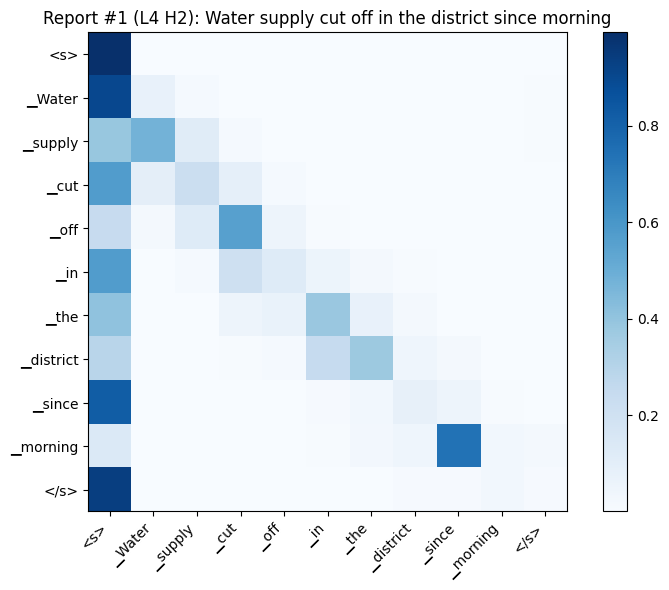

✅ Attention Map #1 Completed!


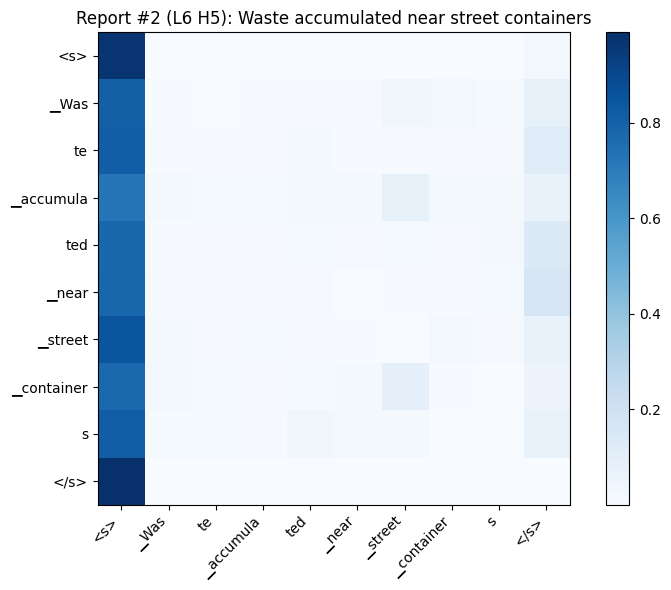

✅ Attention Map #2 Completed!


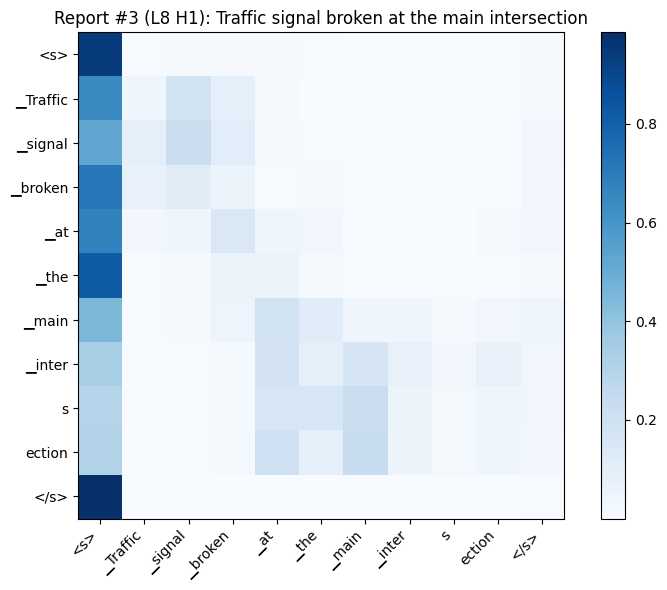

✅ Attention Map #3 Completed!

✅ All Attention Maps Completed!


In [61]:
# Lab 2 - Code 6: Attention Maps
from transformers import AutoTokenizer, AutoModel
import torch
import matplotlib.pyplot as plt

# Load Model
name = "xlm-roberta-base"
tok = AutoTokenizer.from_pretrained(name)
model = AutoModel.from_pretrained(
    name, attn_implementation="eager"
).eval()

# Change the texts here (more than one municipal report in English)
texts = [
    "Water supply cut off in the district since morning",
    "Waste accumulated near street containers",
    "Traffic signal broken at the main intersection"
]

# Different layers/heads per sample so outputs and maps vary cleanly
layer_head_pairs = [(4, 2), (6, 5), (8, 1)]

for idx, text in enumerate(texts):
    # Calculate Attention
    inputs = tok(text, return_tensors="pt")

    with torch.no_grad():
        att = model(**inputs, output_attentions=True).attentions

    # Display Attention Map
    tokens = tok.convert_ids_to_tokens(inputs["input_ids"][0])
    layer_idx, head_idx = layer_head_pairs[idx]

    plt.figure(figsize=(8, 6))
    plt.imshow(att[layer_idx][0, head_idx].numpy(), cmap="Blues")
    plt.xticks(range(len(tokens)), tokens, rotation=45, ha="right")
    plt.yticks(range(len(tokens)), tokens)
    plt.title(f"Report #{idx + 1} (L{layer_idx} H{head_idx}): {text}")
    plt.colorbar()
    plt.tight_layout()
    plt.show()

    print(f"✅ Attention Map #{idx + 1} Completed!")

print("\n✅ All Attention Maps Completed!")

In [62]:
# Lab 2 - Code 7: PAD Leak Detection
pad_length = 30

pad_texts = [
    "انقطاع المياه عن الحي منذ الصباح الباكر",
    "تعطل الإشارة المرورية عند التقاطع الرئيسي",
    "تراكم النفايات قرب الحاويات في الشارع العام",
    "تسرب مياه تحت الرصيف يحتاج صيانة عاجلة"
]

for idx, sample_text in enumerate(pad_texts):
    size = max(pad_length, len(tok.encode(sample_text)) + 5)
    inputs = tok(
        sample_text,
        return_tensors="pt",
        padding="max_length",
        max_length=size
    )

    with torch.no_grad():
        with_mask = model(**inputs, output_attentions=True).attentions[0][0, 0]
        without_mask = model(
            input_ids=inputs["input_ids"],
            output_attentions=True
        ).attentions[0][0, 0]

    pads = inputs["attention_mask"][0] == 0
    valid = ~pads

    print("\n" + "=" * 50)
    print(f"✅ PAD Leak Test Completed! (Report #{idx + 1})")
    print("Text:", sample_text)
    print("Padded Length:", size)
    print("PAD Count:", pads.sum().item())
    print("With Mask:", round(with_mask[valid][:, pads].sum(-1).mean().item(), 4))
    print("Without Mask:", round(without_mask[valid][:, pads].sum(-1).mean().item(), 4))


✅ PAD Leak Test Completed! (Report #1)
Text: انقطاع المياه عن الحي منذ الصباح الباكر
Padded Length: 30
PAD Count: 19
With Mask: 0.0
Without Mask: 0.1935

✅ PAD Leak Test Completed! (Report #2)
Text: تعطل الإشارة المرورية عند التقاطع الرئيسي
Padded Length: 30
PAD Count: 19
With Mask: 0.0
Without Mask: 0.2109

✅ PAD Leak Test Completed! (Report #3)
Text: تراكم النفايات قرب الحاويات في الشارع العام
Padded Length: 30
PAD Count: 16
With Mask: 0.0
Without Mask: 0.1581

✅ PAD Leak Test Completed! (Report #4)
Text: تسرب مياه تحت الرصيف يحتاج صيانة عاجلة
Padded Length: 30
PAD Count: 18
With Mask: 0.0
Without Mask: 0.1665


### Lap 3 A

In [63]:
import pandas as pd

data = {
    "citizen_id": [1, 1, 2, 2, 3, 3, 4, 4, 5, 5, 6, 6],
    "text": [
        "انقطاع المياه عن الحي منذ الصباح الباكر",
        "تسرب مياه تحت الرصيف يحتاج صيانة عاجلة",
        "تعطل الإشارة المرورية عند التقاطع الرئيسي",
        "وجود حفرة عميقة في منتصف الطريق",
        "تراكم النفايات قرب الحاويات في الشارع العام",
        "تأخر رفع المخلفات المنزلية في الحي",
        "تلف إنارة الممر والمشاة ليلاً",
        "أعمدة الإنارة مطفأة في الشارع الفرعي",
        "لا أستطيع تقديم البلاغ عبر الخدمة الإلكترونية",
        "التطبيق البلدي يغلق عند إرفاق الصور",
        "تضرر الأسفلت بعد هطول الأمطار",
        "مشكلة في ضغط شبكة المياه بالمنطقة"
    ],
    "topic": [
        "water",
        "water",
        "roads",
        "roads",
        "waste",
        "waste",
        "lighting",
        "lighting",
        "digital_services",
        "digital_services",
        "roads",
        "water"
    ]
}

df = pd.DataFrame(data)

topics = sorted(df["topic"].unique())
label_map = {topic: i for i, topic in enumerate(topics)}
df["label"] = df["topic"].map(label_map)

print(df)
print("\nLabels:", label_map)

    citizen_id                                           text  \
0            1        انقطاع المياه عن الحي منذ الصباح الباكر   
1            1         تسرب مياه تحت الرصيف يحتاج صيانة عاجلة   
2            2      تعطل الإشارة المرورية عند التقاطع الرئيسي   
3            2                وجود حفرة عميقة في منتصف الطريق   
4            3    تراكم النفايات قرب الحاويات في الشارع العام   
5            3             تأخر رفع المخلفات المنزلية في الحي   
6            4                  تلف إنارة الممر والمشاة ليلاً   
7            4           أعمدة الإنارة مطفأة في الشارع الفرعي   
8            5  لا أستطيع تقديم البلاغ عبر الخدمة الإلكترونية   
9            5            التطبيق البلدي يغلق عند إرفاق الصور   
10           6                  تضرر الأسفلت بعد هطول الأمطار   
11           6              مشكلة في ضغط شبكة المياه بالمنطقة   

               topic  label  
0              water      4  
1              water      4  
2              roads      2  
3              roads      2  
4   

In [64]:
from sklearn.model_selection import GroupShuffleSplit

test_size = 0.25
random_state = 101
group_column = "citizen_id"

gss = GroupShuffleSplit(
    n_splits=1,
    test_size=test_size,
    random_state=random_state
)

train_idx, test_idx = next(
    gss.split(df, groups=df[group_column])
)

train_df = df.iloc[train_idx]
test_df = df.iloc[test_idx]

shared = set(train_df[group_column]) & set(test_df[group_column])

print("Train:", len(train_df))
print("Test:", len(test_df))
print("Shared Citizens:", shared)

Train: 8
Test: 4
Shared Citizens: set()


In [65]:
from transformers import AutoTokenizer
from datasets import Dataset

tokenizer = AutoTokenizer.from_pretrained("CAMeL-Lab/bert-base-arabic-camelbert-mix")

sample_texts = [
    "انقطاع المياه عن الحي منذ الصباح الباكر",
    "تعطل الإشارة المرورية عند التقاطع الرئيسي",
    "تراكم النفايات قرب الحاويات في الشارع العام"
]

def prepare_data(data):
    tokens = tokenizer(data["text"].tolist(), padding=True, truncation=True)
    tokens["labels"] = data["label"].tolist()
    return Dataset.from_dict(tokens)

train_dataset = prepare_data(train_df)
test_dataset = prepare_data(test_df)

for idx, s_text in enumerate(sample_texts):
    print("\n" + "-" * 45)
    print(f"Sample #{idx + 1}: {s_text}")
    print("Tokens:", tokenizer.tokenize(s_text))
    print("Input IDs:", tokenizer.encode(s_text))

print("\n✅ Dataset Ready!")
print("Train:", len(train_dataset), "| Test:", len(test_dataset))


---------------------------------------------
Sample #1: انقطاع المياه عن الحي منذ الصباح الباكر
Tokens: ['انقطاع', 'المياه', 'عن', 'الحي', 'منذ', 'الصباح', 'الباك', '##ر']
Input IDs: [2, 17398, 3093, 1955, 3593, 2837, 4235, 11817, 1017, 3]

---------------------------------------------
Sample #2: تعطل الإشارة المرورية عند التقاطع الرئيسي
Tokens: ['تعطل', 'الإشارة', 'المرورية', 'عند', 'التقاط', '##ع', 'الرئيسي']
Input IDs: [2, 22321, 13492, 23685, 2192, 22498, 1009, 8058, 3]

---------------------------------------------
Sample #3: تراكم النفايات قرب الحاويات في الشارع العام
Tokens: ['تراكم', 'النفايات', 'قرب', 'الحا', '##ويات', 'في', 'الشارع', 'العام']
Input IDs: [2, 20769, 18531, 4795, 4325, 4318, 1912, 7423, 2169, 3]

✅ Dataset Ready!
Train: 8 | Test: 4


In [66]:
from transformers import AutoModelForSequenceClassification

num_labels = len(topics)

model = AutoModelForSequenceClassification.from_pretrained(
    "CAMeL-Lab/bert-base-arabic-camelbert-mix",
    num_labels=num_labels
)

print("✅ Model Ready!")
print("Number of Labels:", num_labels)
print("Topics:", topics)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: CAMeL-Lab/bert-base-arabic-camelbert-mix
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSIN

✅ Model Ready!
Number of Labels: 5
Topics: ['digital_services', 'lighting', 'roads', 'waste', 'water']


In [67]:
from transformers import TrainingArguments, Trainer

epochs = 5
batch_size = 4
learning_rate = 3e-5

args = TrainingArguments(
    output_dir="./results",
    num_train_epochs=epochs,
    per_device_train_batch_size=batch_size,
    learning_rate=learning_rate,
    report_to="none"
)

trainer = Trainer(
    model=model,
    args=args,
    train_dataset=train_dataset,
    eval_dataset=test_dataset
)

trainer.train()
print("✅ Training Complete!")
print(trainer.evaluate())

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Step,Training Loss


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

✅ Training Complete!


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Training Loss,Validation Loss,Step
No log,2.245673,10


{'eval_loss': 2.2456727027893066}


LAP 3B

In [68]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained(
    "CAMeL-Lab/bert-base-arabic-camelbert-mix"
)

samples = [
    {
        "words": ["تسرب", "مياه", "في", "حي", "السعادة"],
        "labels": ["B-ISSUE", "I-ISSUE", "O", "B-LOC", "I-LOC"]
    },
    {
        "words": ["تعطل", "إشارة", "المرور", "عند", "تقاطع", "الملك", "فهد"],
        "labels": ["B-ISSUE", "I-ISSUE", "I-ISSUE", "O", "B-LOC", "I-LOC", "I-LOC"]
    },
    {
        "words": ["تراكم", "نفايات", "قرب", "الرصيف", "في", "الفيحاء"],
        "labels": ["B-ISSUE", "I-ISSUE", "O", "B-LOC", "O", "B-LOC"]
    }
]

for idx, item in enumerate(samples):
    words = item["words"]
    labels = item["labels"]

    tokens = tokenizer(words, is_split_into_words=True)

    print("\n" + "=" * 50)
    print(f"Sample #{idx + 1}: {' '.join(words)}")
    print("Tokens:", tokenizer.convert_ids_to_tokens(tokens["input_ids"]))
    print("Word IDs:", tokens.word_ids())
    print("Labels:", labels)


Sample #1: تسرب مياه في حي السعادة
Tokens: ['[CLS]', 'تسرب', 'مياه', 'في', 'حي', 'السعادة', '[SEP]']
Word IDs: [None, 0, 1, 2, 3, 4, None]
Labels: ['B-ISSUE', 'I-ISSUE', 'O', 'B-LOC', 'I-LOC']

Sample #2: تعطل إشارة المرور عند تقاطع الملك فهد
Tokens: ['[CLS]', 'تعطل', 'إشارة', 'المرور', 'عند', 'تقاطع', 'الملك', 'فهد', '[SEP]']
Word IDs: [None, 0, 1, 2, 3, 4, 5, 6, None]
Labels: ['B-ISSUE', 'I-ISSUE', 'I-ISSUE', 'O', 'B-LOC', 'I-LOC', 'I-LOC']

Sample #3: تراكم نفايات قرب الرصيف في الفيحاء
Tokens: ['[CLS]', 'تراكم', 'نف', '##ايات', 'قرب', 'الرص', '##يف', 'في', 'الفي', '##حاء', '[SEP]']
Word IDs: [None, 0, 1, 1, 2, 3, 3, 4, 5, 5, None]
Labels: ['B-ISSUE', 'I-ISSUE', 'O', 'B-LOC', 'O', 'B-LOC']


In [69]:
report_samples = [
    ["تسرب", "مياه", "في", "حي", "السعادة"],
    ["تراكم", "نفايات", "قرب", "الرصيف", "في", "الفيحاء"],
    ["تعطل", "إشارة", "المرور", "عند", "تقاطع", "الملك", "فهد"],
    ["تلف", "إنارة", "الشارع", "بجانب", "الحديقة"]
]

for idx, words in enumerate(report_samples):
    tokens = tokenizer(words, is_split_into_words=True)
    word_ids = tokens.word_ids()
    token_list = tokenizer.convert_ids_to_tokens(tokens["input_ids"])

    print("\n" + "=" * 50)
    print(f"Sample #{idx + 1}: {' '.join(words)}")
    previous = None
    for token, word_id in zip(token_list, word_ids):
        if word_id is None:
            status = "Special"
        elif word_id != previous:
            status = "First"
        else:
            status = "Continuation"

        print(f"{token} -> {status}")
        previous = word_id


Sample #1: تسرب مياه في حي السعادة
[CLS] -> Special
تسرب -> First
مياه -> First
في -> First
حي -> First
السعادة -> First
[SEP] -> Special

Sample #2: تراكم نفايات قرب الرصيف في الفيحاء
[CLS] -> Special
تراكم -> First
نف -> First
##ايات -> Continuation
قرب -> First
الرص -> First
##يف -> Continuation
في -> First
الفي -> First
##حاء -> Continuation
[SEP] -> Special

Sample #3: تعطل إشارة المرور عند تقاطع الملك فهد
[CLS] -> Special
تعطل -> First
إشارة -> First
المرور -> First
عند -> First
تقاطع -> First
الملك -> First
فهد -> First
[SEP] -> Special

Sample #4: تلف إنارة الشارع بجانب الحديقة
[CLS] -> Special
تلف -> First
إنا -> First
##رة -> Continuation
الشارع -> First
بجانب -> First
الحديقة -> First
[SEP] -> Special


In [70]:
clitic_batches = [
    ["والمياه", "بالطريق", "والنفايات"],
    ["للصيانة", "والمجاري", "بالحي"],
    ["كالإنارة", "والأرصفة", "بالشارع"]
]

for idx, words in enumerate(clitic_batches):
    tokens = tokenizer(words, is_split_into_words=True)
    token_list = tokenizer.convert_ids_to_tokens(tokens["input_ids"])

    print(f"\n--- Batch {idx + 1} ---")
    for token, word_id in zip(token_list, tokens.word_ids()):
        print(f"{token} -> {word_id}")


--- Batch 1 ---
[CLS] -> None
والمياه -> 0
بالط -> 1
##ريق -> 1
والن -> 2
##فايات -> 2
[SEP] -> None

--- Batch 2 ---
[CLS] -> None
للص -> 0
##يانة -> 0
والمج -> 1
##اري -> 1
بالحي -> 2
[SEP] -> None

--- Batch 3 ---
[CLS] -> None
كال -> 0
##إ -> 0
##نا -> 0
##رة -> 0
والأ -> 1
##رص -> 1
##فة -> 1
بالش -> 2
##ارع -> 2
[SEP] -> None


In [71]:
tests = [
    ["تسرب", "مياه"],
    ["مياه", "في", "الفيحاء"],
    ["السعادة", "حي"],
    ["تراكم", "نفايات"],
    ["قرب", "الرصيف"],
    ["نفايات", "بالطريق"],
    ["تعطل", "إشارة"],
    ["الرصيف", "نظيف"]
]

passed = 0

for idx, words in enumerate(tests):
    encoded = tokenizer(words, is_split_into_words=True)
    ids = encoded.word_ids()
    found = set(i for i in ids if i is not None)

    is_ok = found == set(range(len(words)))
    if is_ok:
        passed += 1

    print(f"Test #{idx + 1} {words} -> {'PASS' if is_ok else 'FAIL'} | Found IDs: {sorted(found)}")

print(f"\nPassed: {passed}/{len(tests)}")

Test #1 ['تسرب', 'مياه'] -> PASS | Found IDs: [0, 1]
Test #2 ['مياه', 'في', 'الفيحاء'] -> PASS | Found IDs: [0, 1, 2]
Test #3 ['السعادة', 'حي'] -> PASS | Found IDs: [0, 1]
Test #4 ['تراكم', 'نفايات'] -> PASS | Found IDs: [0, 1]
Test #5 ['قرب', 'الرصيف'] -> PASS | Found IDs: [0, 1]
Test #6 ['نفايات', 'بالطريق'] -> PASS | Found IDs: [0, 1]
Test #7 ['تعطل', 'إشارة'] -> PASS | Found IDs: [0, 1]
Test #8 ['الرصيف', 'نظيف'] -> PASS | Found IDs: [0, 1]

Passed: 8/8


In [72]:
evaluation_cases = [
    {
        "name": "Case #1 — Water Leak Report",
        "y_true": ["B-ISSUE", "I-ISSUE", "O", "B-LOC", "I-LOC"],
        "y_pred": ["B-ISSUE", "I-ISSUE", "O", "B-LOC", "I-LOC"]
    },
    {
        "name": "Case #2 — Road & Waste Report",
        "y_true": ["B-ISSUE", "I-ISSUE", "O", "B-LOC", "O", "B-LOC"],
        "y_pred": ["B-ISSUE", "O", "O", "B-LOC", "O", "I-LOC"]
    },
    {
        "name": "Case #3 — Street Lighting Report",
        "y_true": ["B-ISSUE", "I-ISSUE", "I-ISSUE", "O", "B-LOC", "I-LOC"],
        "y_pred": ["B-ISSUE", "I-ISSUE", "O", "O", "B-LOC", "I-LOC"]
    }
]

for case in evaluation_cases:
    y_true = case["y_true"]
    y_pred = case["y_pred"]
    correct = sum(t == p for t, p in zip(y_true, y_pred))
    accuracy = (correct / len(y_true)) * 100

    print("\n" + "=" * 50)
    print(case["name"])
    print(f"Correct: {correct}/{len(y_true)} | Accuracy: {accuracy:.1f}%")


Case #1 — Water Leak Report
Correct: 5/5 | Accuracy: 100.0%

Case #2 — Road & Waste Report
Correct: 4/6 | Accuracy: 66.7%

Case #3 — Street Lighting Report
Correct: 5/6 | Accuracy: 83.3%


Lap 4

In [73]:
#lap 4 import re





def normalize_arabic(text):

    text = re.sub(r"[إأآا]", "ا", text)

    text = re.sub(r"ى", "ي", text)

    text = re.sub(r"ة", "ه", text)

    return text


text = "أنفطاع المياة في البيت"

text = "أبغى أبلغ عن أنقطاع المياة"

print("Before:", text)

print("After :", normalize_arabic(text))




Before: أبغى أبلغ عن أنقطاع المياة
After : ابغي ابلغ عن انقطاع المياه


In [74]:
texts = [

    "وش وضع أنقطاع المياة",

    "الموية مقطوعة من أمس في الحي",

      "وش وضع بلاغي عن المخالفة ",

      "فيه نفايات متراكمة بالحاوية",

]


for text in texts:

    print(text)

وش وضع أنقطاع المياة
الموية مقطوعة من أمس في الحي
وش وضع بلاغي عن المخالفة 
فيه نفايات متراكمة بالحاوية


In [75]:
ext ="بالحاوية"





print("Original:", text)

print("Segmented:  ب + ال + حاوية")

Original: فيه نفايات متراكمة بالحاوية
Segmented:  ب + ال + حاوية


In [76]:
models = {

    "CAMeLBERT-mix": 0.92,

    "CAMeLBERT-DA": 0.99,

}


for model, score in models.items():

    print(model, "→ Macro-F1:", score)

CAMeLBERT-mix → Macro-F1: 0.92
CAMeLBERT-DA → Macro-F1: 0.99


In [77]:
texts = [

    "وش فيه البلاغ",

    "أبي أقدم على الخدمة",

    "ليه بلاغي للحين ما قبل؟",

    "الموية مقطوعة من أمس",

    "أبغى أعرف ليه مقطوعة الموية"

]


for text in texts:

    print("Original:", text)


print("Ready for fine-tuning")

Original: وش فيه البلاغ
Original: أبي أقدم على الخدمة
Original: ليه بلاغي للحين ما قبل؟
Original: الموية مقطوعة من أمس
Original: أبغى أعرف ليه مقطوعة الموية
Ready for fine-tuning


Lap 5

In [78]:
!pip install -q sentence-transformers faiss-cpu


from sentence_transformers import SentenceTransformer

import faiss


texts = [

    "انقطعت الموية عن الحي",

    "مشكلة في فاتورة المياة",

    "يوجد خلل في المياه",

]


model = SentenceTransformer(

    "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"

)


embeddings = model.encode(texts)


index = faiss.IndexFlatL2(embeddings.shape[1])


index.add(embeddings)


print("عدد النصوص في FAISS:", index.ntotal)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

عدد النصوص في FAISS: 3


In [79]:
query = "الموية لا تعمل"


query_embedding = model.encode([query])


distances, indices = index.search(query_embedding, 2)


print("Query:", query)

print("Results:")


for i in indices[0]:

    print("-", texts[i])

Query: الموية لا تعمل
Results:
- انقطعت الموية عن الحي
- مشكلة في فاتورة المياة


In [80]:
results = [

    "مشكلة في فاتورة المياة",

    "انقطعت الموية عن الحي",

    "يوجد خلل في المياه"

]


correct_answer = "انقطعت الموية عن الحي"


rank = results.index(correct_answer) + 3


recall_at_10 = 1 if rank <= 10 else 0

mrr_at_10 = 1 / rank


print("Recall@10:", recall_at_10)

print("MRR@10:", mrr_at_10)

Recall@10: 1
MRR@10: 0.25


In [81]:
from sentence_transformers import CrossEncoder


query = "الموية لا تعمل"


results = [

    "مشكلة في فاتورة المياة",

    "انقطعت المياة عن الحي",

    "يوجد خلل في المياه"

]


reranker = CrossEncoder(

    "cross-encoder/mmarco-mMiniLMv2-L12-H384-v1"

)


pairs = [[query, text] for text in results]


scores = reranker.predict(pairs)


for text, score in zip(results, scores):

    print(round(float(score), 2), "→", text)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

-3.46 → مشكلة في فاتورة المياة
-1.96 → انقطعت المياة عن الحي
-5.25 → يوجد خلل في المياه


Lap 6

In [82]:
reports = [
    {"language": "Arabic", "dialect": "Saudi", "length": "Short", "correct": 1},
    {"language": "Arabic", "dialect": "Saudi", "length": "Long", "correct": 1},
    {"language": "Arabic", "dialect": "MSA", "length": "Short", "correct": 1},
    {"language": "Arabic", "dialect": "Egyptian", "length": "Short", "correct": 0},
    {"language": "English", "dialect": "Standard", "length": "Long", "correct": 0}
]

for report in reports:
    print(
        report["language"],
        "|", report["dialect"],
        "|", report["length"],
        "| Correct:", report["correct"]
    )

Arabic | Saudi | Short | Correct: 1
Arabic | Saudi | Long | Correct: 1
Arabic | MSA | Short | Correct: 1
Arabic | Egyptian | Short | Correct: 0
English | Standard | Long | Correct: 0


In [83]:
import numpy as np
from sklearn.metrics import accuracy_score

# 1 = بلاغ طارئ (تسرب مياه)، 0 = بلاغ خدمة عامة (مرور / نفايات)
y_true = np.array([1, 0, 1, 1, 0, 0, 1, 0, 1, 1])
y_pred = np.array([1, 0, 1, 0, 1, 0, 0, 1, 0, 1])

scores = []

for _ in range(1000):
    i = np.random.choice(len(y_true), len(y_true), replace=True)
    scores.append(accuracy_score(y_true[i], y_pred[i]))

print("95% CI:", np.percentile(scores, 2.5), "-", np.percentile(scores, 97.5))

95% CI: 0.2 - 0.8


In [84]:
errors = [
    ("الموية مقطوعة عن البيت", "انقطاع المياه", "تراكم النفايات"),
    ("الموية تقطر", "تسرب المياه", "تسرب المياه"),
    ("الزبالة متكدسة عند الحي", "تراكم النفايات", "ازدحام مروري"),
    ("كيف أحجز تذكرة ؟", "خارج النطاق", "تسرب المياه")
]

for text, actual, predicted in errors:
    print("البلاغ:", text)
    print("التصنيف الصحيح:", actual)
    print("توقع النموذج:", predicted)
    print("التقييم:", "صحيح" if actual == predicted else "خطأ")
    print("-" * 30)

البلاغ: الموية مقطوعة عن البيت
التصنيف الصحيح: انقطاع المياه
توقع النموذج: تراكم النفايات
التقييم: خطأ
------------------------------
البلاغ: الموية تقطر
التصنيف الصحيح: تسرب المياه
توقع النموذج: تسرب المياه
التقييم: صحيح
------------------------------
البلاغ: الزبالة متكدسة عند الحي
التصنيف الصحيح: تراكم النفايات
توقع النموذج: ازدحام مروري
التقييم: خطأ
------------------------------
البلاغ: كيف أحجز تذكرة ؟
التصنيف الصحيح: خارج النطاق
توقع النموذج: تسرب المياه
التقييم: خطأ
------------------------------


In [85]:
report = {
    "Domain": "Municipal Services (Water, Traffic, Waste)",
    "Sliced Evaluation": "Language, Dialect (Saudi/MSA/Egyptian), Length",
    "Confidence Interval": "95%",
    "Error Analysis": "Completed (Water, Waste, Traffic, Out-of-Scope)",
    "Error Taxonomy": "Completed"
}

for key, value in report.items():
    print(key, ":", value)

Domain : Municipal Services (Water, Traffic, Waste)
Sliced Evaluation : Language, Dialect (Saudi/MSA/Egyptian), Length
Confidence Interval : 95%
Error Analysis : Completed (Water, Waste, Traffic, Out-of-Scope)
Error Taxonomy : Completed
